### Congressional Trading Full Analysis
Objective: Turn each disclosed trade into a long (if buy) or short (sell) position

Plan:
1. Data exploration: who, what, when trades are and how late its disclosed
2. Does copying congress produce returns better than baseline (i.e S&P) - specifically after the filing date
3. How price generally moves before and after a trade
4. Reps. vs Dems.
5. Membership Leaderboard (who we should follow)
6. More insights into data
7. Potential baktesting

Horizons: [5d, 21d, 63d, 126d]
Long Return = (exit - entry) / entry
Short Return = (entry - exit) / entry
Excess return = position return - benchmark (flipped for short, so pos num = trade beat market)
No fees


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path



PARTY_COLOURS = {"Democrat": "#0000ff", "Republican": "#ff0000","Independent": "#8a8a8a"}



### Trades Data Collection

In [2]:
trades_df = pd.read_parquet("../data/processed/tradesAInvestALL.parquet")

# Adjusting ticker name to match with yfinance data
trades_df["ticker"] = trades_df["ticker"].replace({"BRK.B": "BRK-B"})

#Making datetime dtype same
trades_df["trade_date"] = pd.to_datetime(trades_df["trade_date"]).astype("datetime64[us]").dt.normalize()
trades_df["filing_date"] = pd.to_datetime(trades_df["filing_date"]).astype("datetime64[us]").dt.normalize()

print(trades_df.shape)
trades_df.head()


(4422, 10)


,id,size,reporting_gap,name,trade_type,filing_date,state,trade_date,party,ticker
0,H002482383202608110036,$100K-$250K,29 Days,Cory Anthony Booker,sell,2026-09-09,NJ,2026-08-11,Democrat,AMZN
1,H002482383202608110038,$100K-$250K,29 Days,Cory Anthony Booker,sell,2026-09-09,NJ,2026-08-11,Democrat,AMZN
2,H002482383202608110037,$100K-$250K,29 Days,Cory Anthony Booker,sell,2026-09-09,NJ,2026-08-11,Democrat,AMZN
3,H002482383202608110040,$100K-$250K,29 Days,Cory Anthony Booker,sell,2026-09-09,NJ,2026-08-11,Democrat,AMZN
4,H002482383202608110042,$100K-$250K,29 Days,Cory Anthony Booker,sell,2026-09-09,NJ,2026-08-11,Democrat,AMZN


In [4]:
trades_df[trades_df.isna().any(axis=1)]
# Don't know how to deal with NaN states, but can deal with NaN party (independent)
trades_df["party"] = trades_df["party"].fillna("Independent")

# get reporting gap (easier this way)
trades_df["lag_days"] = (trades_df["filing_date"] - trades_df["trade_date"]).dt.days

trades_df["position"] = trades_df["trade_type"].map({"buy": "long", "sell": "short"})
trades_df["sign"] = trades_df["trade_type"].map({"buy": 1, "sell": -1})

In [5]:
trades_df.columns.tolist()

['id',
 'size',
 'reporting_gap',
 'name',
 'trade_type',
 'filing_date',
 'state',
 'trade_date',
 'party',
 'ticker',
 'lag_days',
 'position',
 'sign']

Trade Size: most are disclosed in a dollar range, but some are exact value, so lets parse and fix

In [8]:
def parse_amount(text):
    text = text.strip().replace("$","").replace(",","")
    mult = 1
    if text.endswith("K"):
        mult, text = 1_000, text[:-1]
    elif text.endswith("M"):
        mult, text = 1_000_000, text[:-1]
    return float(text) * mult

def parse_size(size):
    parts = size.split("-")
    low = parse_amount(parts[0])
    high = parse_amount(parts[1]) if len(parts) > 1 else low
    return pd.Series({"size_low": low, "size_high": high, "size_mid": (low + high) / 2})

trades_df = pd.concat([trades_df,trades_df["size"].apply(parse_size)], axis=1)

size_bins = [0, 15_000, 50_000, 100_000, 250_000, np.inf]
size_labels = ["<=15K", "15K-50K", "50K-100K", "100K-250K", ">250K"]
trades_df["size_fixed"] = pd.cut(trades_df["size_high"], bins=size_bins,labels=size_labels)

trades_df["size_fixed"].value_counts().sort_index()

size_fixed
<=15K        2651
15K-50K      1049
50K-100K      344
100K-250K     235
>250K         143
Name: count, dtype: int64

### Stock Data Collection

In [10]:
stock_dir = Path("../data/raw/stock_prices")
stock_files = list(stock_dir.glob("*.parquet"))

stock_data = {}
for file in stock_files:
    ticker = file.stem
    stock_data[ticker] = pd.read_parquet(file)

for ticker, df in stock_data.items():
    df.index = pd.to_datetime(df.index).astype("datetime64[us]").normalize()

# Creating table closing price rows: trading days, cols: tickers
close = pd.DataFrame({ticker: df["Close"][ticker] for ticker, df in stock_data.items()}).sort_index()
TICKERS = close.columns.tolist()
print(TICKERS)
print(close.index.min().date(), "->", close.index.max().date())

['AMZN', 'NVDA', 'AAPL', 'META', 'DELL', 'BRK-B', 'SMCI', 'GOOGL', 'MSFT', 'JNJ', 'UNH']
2016-01-04 -> 2026-10-07


Collecting S&P 500 data for timeframe

In [12]:
spy_file = Path("../data/full_close.parquet")

if not spy_file.exists():
    try:
        import yfinance as yf
        spy_raw = yf.download("SPY", start="2016-01-01",end=None,interval="1d",progress=False)
        if len(spy_raw) > 0:
            spy_raw.to_parquet(spy_file)
            print(f"spy file downloaded w/ {len(spy_raw)} rows saved to {spy_file}")
        else:
            print("spy download came back empty")
    except Exception as e:
        print("couldn't download: ",e)

if spy_file.exists():
    spy_raw = pd.read_parquet(spy_file)
    spy_raw.index = pd.to_datetime(spy_raw.index).astype("datetime64[us]").normalize()
    spy_close = spy_raw["Close"]["SPY"].reindex(close.index).ffill()
    HAVE_SPY = True
else:
    spy_close = pd.Series(np.nan, index=close.index)
    HAVE_SPY = False

print("Using SPY benchmark:", HAVE_SPY)

Using SPY benchmark: True


In [15]:
#11 stocks traded graph and an average of those 11 and the SPY

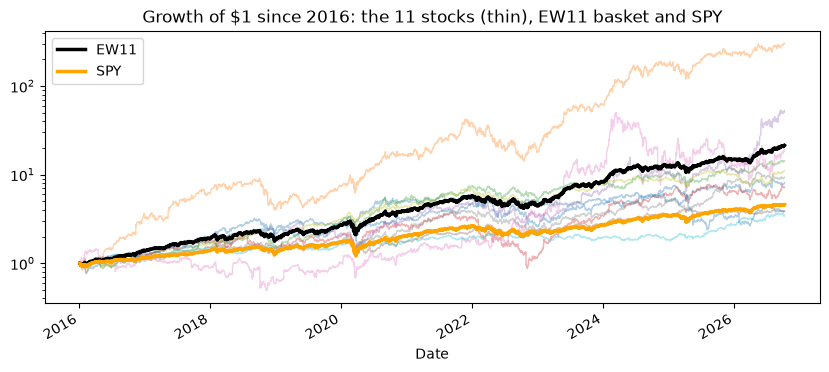

In [16]:
daily_ret = close.pct_change(fill_method=None)

ew_daily = daily_ret.mean(axis=1,skipna=True)
ew_daily.iloc[0] = 0.0
ew_index = (1+ew_daily).cumprod()


bench = pd.DataFrame({"EW11": ew_index, "SPY": spy_close})

fig, ax = plt.subplots(figsize=(10, 4))

(close / close.bfill().iloc[0]).plot(ax=ax, alpha=0.35, lw=1, legend=False)
(ew_index / ew_index.iloc[0]).plot(ax=ax, color="black", lw=2.5, label="EW11")

if HAVE_SPY:
    (spy_close / spy_close.dropna().iloc[0]).plot(ax=ax, color="orange", lw=2.5, label="SPY")

ax.set_yscale("log")
ax.set_title("Growth of $1 since 2016: the 11 stocks (thin), EW11 basket and SPY")
ax.legend(ax.get_lines()[len(TICKERS):], ["EW11", "SPY"] if HAVE_SPY else ["EW11"])
plt.show()

# 1. RAW DATA OVERVIEW

In [17]:
print(f"Trades: {len(trades_df)}")
print(f"Members: {trades_df['name'].nunique()}")
print(f"Trade dates: {trades_df['trade_date'].min().date()} -> {trades_df['trade_date'].max().date()}")


Trades: 4422
Members: 126
Trade dates: 2016-01-13 -> 2026-09-22


In [19]:
print(pd.crosstab(trades_df["party"], trades_df["trade_type"], margins=True))


trade_type    buy  sell   All
party                        
Democrat     1261  1146  2407
Independent     8     4    12
Republican    812  1191  2003
All          2081  2341  4422


In [20]:
print("Members per party:")
print(trades_df.groupby("party")["name"].nunique())

Members per party:
party
Democrat       61
Independent     1
Republican     64
Name: name, dtype: int64


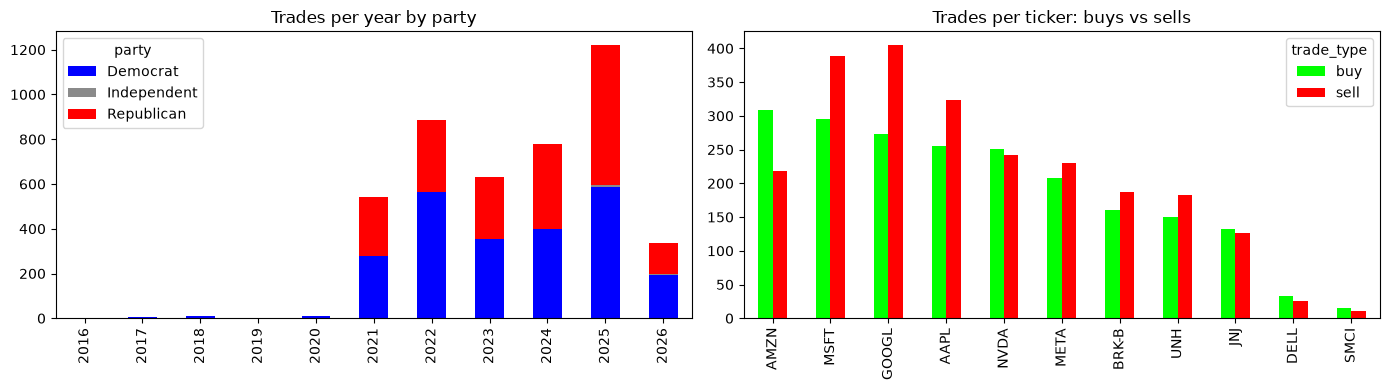

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

per_year = pd.crosstab(trades_df["trade_date"].dt.year, trades_df["party"])
per_year.plot(kind="bar", stacked=True, ax=axes[0], color=[PARTY_COLOURS[p] for p in per_year.columns])
axes[0].set_title("Trades per year by party")
axes[0].set_xlabel("")

per_ticker = pd.crosstab(trades_df["ticker"], trades_df["trade_type"]).sort_values("buy", ascending=False)
per_ticker.plot(kind="bar", ax=axes[1], color=["#00ff00", "#ff0000"])
axes[1].set_title("Trades per ticker: buys vs sells")
axes[1].set_xlabel("")
plt.tight_layout()
plt.show()

pretty much all the data is from 2021-2026

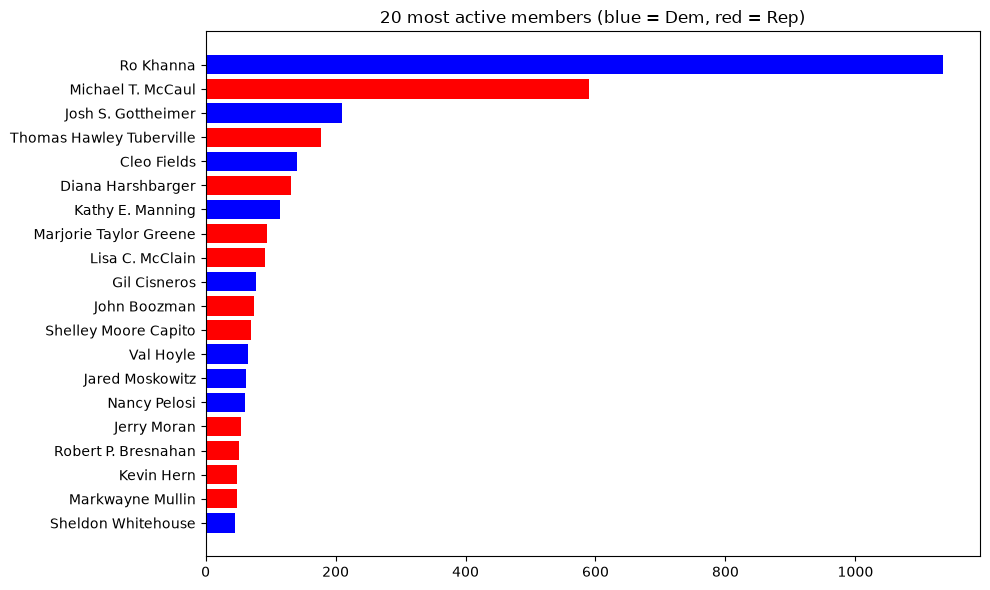

The top 2 traders make up 39% of all trades


In [25]:
top_traders = (trades_df.groupby(["name", "party"]).size()
               .reset_index(name="trades").sort_values("trades", ascending=False).head(20))

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_traders["name"][::-1], top_traders["trades"][::-1],
        color=[PARTY_COLOURS[p] for p in top_traders["party"][::-1]])
ax.set_title("20 most active members (blue = Dem, red = Rep)")
plt.tight_layout()
plt.show()

share = top_traders.head(2)["trades"].sum() / len(trades_df)
print(f"The top 2 traders make up {share:.0%} of all trades")

GAP in reporting (days between actual trade date and when disclosed)

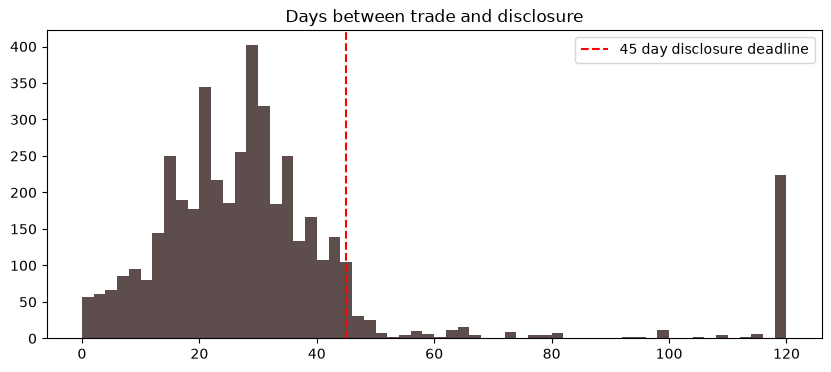

In [26]:
ig, ax = plt.subplots(figsize=(10,4))
ax.hist(trades_df["lag_days"].clip(upper=120),bins=60,color="#5d4d4d")
ax.axvline(45,color="red", ls="--", label="45 day disclosure deadline")
ax.set_title("Days between trade and disclosure")
ax.legend()
plt.show()

In [27]:
print(f"Median lag: {trades_df['lag_days'].median():.0f} days")


Median lag: 28 days


# 2. Computing Returns
Ways of measuring trades success:
- 1) Basic ret : long or short return
- 2) xs_spy : excess return vs the SPY (s&p 500)

In [29]:
HORIZONS = {"5D": 5, "21D": 21, "63D": 63, "126D": 126}

dates = close.index
price_matrix = close.to_numpy()
ticker_col = {t: i for i, t in enumerate(close.columns)}
bench_matrix = {"spy": bench["SPY"].to_numpy()}

In [31]:
fwd_avg = {}
for h_name, h in HORIZONS.items():
    fwd = close.shift(-h) / close - 1 # forward returns (after / before) 
    fwd_avg[h_name] = fwd.groupby(fwd.index.year).mean() # avg for whole year
